# Amazon Reviews Sentiment Analysis: Naive Bayes
**Name / IT Number:** Ediriweera V.S. / `IT25101455`
**Model:** Multinomial / Complement Naive Bayes

This notebook classifies Amazon reviews as positive or negative with Naive Bayes on TF-IDF features. It uses the group's shared settings, the same 300,000-review random sample (seed 42), the same preprocessing, the same 80/20 stratified split, a 100,000-review development subset for tuning, and 5-fold stratified cross-validation.

In [1]:
%matplotlib inline
import os
import re
import random
from pathlib import Path
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report, confusion_matrix)


sns.set_theme(style="whitegrid")
STUDENT_ID = "IT25101455"

# settings
SEED = 42
SAMPLE_SIZE = 300000
DATA_PATH = "../data/raw/train.ft.txt"
OUT_DIR = Path("../results/outputs")
FIG_DIR = Path("../results/eda_visualizations")
METRICS_DIR = Path("../results/final_metrics")
for folder in (OUT_DIR, FIG_DIR, METRICS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# stop here if the dataset is missing
assert os.path.exists(DATA_PATH), "train.ft.txt not found in data/raw/"

## 1. Load and preprocess the data
The same steps are used in all six notebooks, so every model is trained and tested on exactly the same reviews:
1. a random sample of 300,000 reviews from `train.ft.txt` (seed 42; the file is sorted, so the first rows would give a biased sample)
2. removing missing values and duplicate reviews
3. text cleaning (lowercase; remove HTML tags, links, numbers and punctuation)
4. removing outliers in review length with the IQR method
5. an 80/20 stratified train/test split (random_state = 42)

Labels: **0 = Negative, 1 = Positive**.

In [2]:
# load a random sample of the reviews
with open(DATA_PATH, "r", encoding="utf-8") as f:
    total_lines = sum(1 for _ in f)

random.seed(SEED)
keep = set(random.sample(range(total_lines), SAMPLE_SIZE))

labels, texts = [], []
with open(DATA_PATH, "r", encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i in keep:
            tag, _, text = line.strip().partition(" ")
            labels.append(1 if tag == "__label__2" else 0)   # 1 = positive, 0 = negative
            texts.append(text)
df = pd.DataFrame({"label": labels, "text": texts})

# missing values and duplicates
df["text"] = df["text"].replace("", np.nan)
df = df.dropna(subset=["text"]).drop_duplicates(subset="text").reset_index(drop=True)

# text cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)             # html tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # links
    text = re.sub(r"[^a-z\s]", " ", text)          # keep letters only
    return re.sub(r"\s+", " ", text).strip()

df["clean_text"] = df["text"].apply(clean_text)
df["word_count"] = df["clean_text"].str.split().str.len()

# outlier removal on review length (IQR method)
q1, q3 = df["word_count"].quantile([0.25, 0.75])
iqr = q3 - q1
df = df[(df["word_count"] >= q1 - 1.5 * iqr) &
        (df["word_count"] <= q3 + 1.5 * iqr)].reset_index(drop=True)

# 80/20 stratified train/test split
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# 5-fold stratified cross-validation and a smaller subset of the training data for tuning
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def dev_subset(data, n=100000):
    subset, _ = train_test_split(data, train_size=n, stratify=data["label"], random_state=SEED)
    return subset.reset_index(drop=True)

print(f"full file: {total_lines:,} reviews | after preprocessing: {len(df):,}")
print(f"train: {len(train_df):,} | test: {len(test_df):,}")
print("positive share (train / test):", round(train_df["label"].mean(), 4), round(test_df["label"].mean(), 4))

full file: 3,600,000 reviews | after preprocessing: 299,983
train: 239,986 | test: 59,997
positive share (train / test): 0.5002 0.5002


In [3]:
# version of the text without stop words (one preprocessing variant)
def remove_stopwords(text):
    return " ".join(w for w in text.split() if w not in ENGLISH_STOP_WORDS and len(w) > 2)

for d in (train_df, test_df):
    d["processed_text"] = d["clean_text"].apply(remove_stopwords)

dev = dev_subset(train_df)                     # 100,000 rows for CV and tuning
y_train, y_test, y_dev = train_df["label"], test_df["label"], dev["label"]
print("train:", len(train_df), "| test:", len(test_df), "| dev subset:", len(dev))
train_df[["clean_text", "processed_text"]].head()

train: 239986 | test: 59997 | dev subset: 100000


,clean_text,processed_text
0,a very dry textbook and i know the others too ...,dry textbook know don waste time book folks dr...
1,horrible horrible horrible need i say more don...,horrible horrible horrible need say dont buy j...
2,easy choreography i love all of the walk away ...,easy choreography love walk away pounds tapes ...
3,one of the best books on vietnam i have ever r...,best books vietnam read book bias agree book d...
4,amazing energy grace i ve been a big fan of de...,amazing energy grace big fan denise duhamel wo...


## 2. Baseline and preprocessing variants

MultinomialNB (alpha = 1.0) with TF-IDF is tested with 5-fold stratified CV on the development subset. Four variants are compared: `processed_text` (stop words removed) or `clean_text` (stop words kept), each with unigrams only or unigrams + bigrams. The baseline is the original notebook's setting: stop words removed, unigrams.

In [4]:
def run_cv(text_col, ngram, model=None, max_features=50000):
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=ngram, max_features=max_features)),
        ("nb", model if model is not None else MultinomialNB(alpha=1.0)),
    ])
    start = time.time()
    s = cross_validate(pipe, dev[text_col], y_dev, cv=CV, scoring=["accuracy", "f1"], n_jobs=-1)
    return {"text_column": text_col, "ngram_range": str(ngram),
            "model": type(pipe.named_steps["nb"]).__name__,
            "cv_accuracy": round(float(s["test_accuracy"].mean()), 4),
            "cv_f1": round(float(s["test_f1"].mean()), 4),
            "cv_std": round(float(s["test_f1"].std()), 4),
            "time_s": round(time.time() - start, 1)}

variant_rows = []
for col in ["processed_text", "clean_text"]:
    for ngram in [(1, 1), (1, 2)]:
        variant_rows.append(run_cv(col, ngram))

variants_df = pd.DataFrame(variant_rows).sort_values("cv_f1", ascending=False)
variants_df

,text_column,ngram_range,model,cv_accuracy,cv_f1,cv_std,time_s
3,clean_text,"(1, 2)",MultinomialNB,0.8879,0.8876,0.0016,21.6
1,processed_text,"(1, 2)",MultinomialNB,0.8664,0.8673,0.0026,17.0
2,clean_text,"(1, 1)",MultinomialNB,0.8458,0.8429,0.0029,8.1
0,processed_text,"(1, 1)",MultinomialNB,0.8376,0.8363,0.0041,5.7


**Observations (section 2)**

- The baseline (stop words removed, unigrams) gives a CV F1 of 0.8363.
- Keeping stop words helps: `clean_text` beats `processed_text` by 0.66 points with unigrams (0.8429 vs 0.8363) and by 2.03 points with bigrams (0.8876 vs 0.8673).
- Bigrams give the biggest gain: +4.47 points on `clean_text` (0.8429 → 0.8876). Phrases such as "not good" and "waste of" are only captured with bigrams.
- The best variant is `clean_text` with bigrams (CV F1 0.8876), 5.13 points above the baseline.

## 3. Hyperparameter tuning

GridSearchCV is run on `clean_text` and compares both Naive Bayes types (MultinomialNB and ComplementNB), the smoothing parameter alpha, the n-gram range and sublinear tf (24 combinations, 5-fold CV, F1).

In [5]:
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=100000)),
    ("nb", MultinomialNB()),
])
param_grid = {
    "nb": [MultinomialNB(), ComplementNB()],
    "nb__alpha": [0.1, 0.3, 1.0],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__sublinear_tf": [True, False],
}
grid = GridSearchCV(pipe, param_grid, cv=CV, scoring="f1", n_jobs=-1,
                    verbose=1, return_train_score=True)

start = time.time()
grid.fit(dev["clean_text"], y_dev)
print(f"time: {(time.time() - start) / 60:.1f} min")
print("best params:", grid.best_params_)
print(f"best CV F1: {grid.best_score_:.4f}")

cv_table = pd.DataFrame(grid.cv_results_)
cv_table["param_nb"] = cv_table["param_nb"].apply(lambda m: type(m).__name__)
cv_table = cv_table[["param_nb", "param_nb__alpha", "param_tfidf__ngram_range",
                     "param_tfidf__sublinear_tf", "mean_train_score", "mean_test_score",
                     "std_test_score", "rank_test_score"]].sort_values("rank_test_score")
cv_table.round(4)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
time: 5.1 min
best params: {'nb': ComplementNB(), 'nb__alpha': 1.0, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
best CV F1: 0.8903


,param_nb,param_nb__alpha,param_tfidf__ngram_range,param_tfidf__sublinear_tf,mean_train_score,mean_test_score,std_test_score,rank_test_score
22,ComplementNB,1.0,"(1, 2)",True,0.9196,0.8903,0.0021,1
10,MultinomialNB,1.0,"(1, 2)",True,0.9196,0.8903,0.0021,2
6,MultinomialNB,0.3,"(1, 2)",True,0.9262,0.8903,0.0019,3
18,ComplementNB,0.3,"(1, 2)",True,0.9262,0.8902,0.0019,4
14,ComplementNB,0.1,"(1, 2)",True,0.9298,0.8898,0.0019,5
2,MultinomialNB,0.1,"(1, 2)",True,0.9298,0.8898,0.0019,6
7,MultinomialNB,0.3,"(1, 2)",False,0.9256,0.8890,0.0018,7
19,ComplementNB,0.3,"(1, 2)",False,0.9256,0.8890,0.0018,8
23,ComplementNB,1.0,"(1, 2)",False,0.9184,0.8890,0.0019,9
11,MultinomialNB,1.0,"(1, 2)",False,0.9184,0.8890,0.0019,10


**Observations (section 3)**

- The best setting is ComplementNB, alpha = 1.0, unigrams + bigrams and `sublinear_tf=True`, with a CV F1 of 0.8903 (std 0.0021).
- MultinomialNB with the same settings also scored 0.8903 (difference below 0.0001). ComplementNB is designed for imbalanced data, so it gives no advantage on this balanced dataset.
- The n-gram range matters most: all 12 bigram settings score 0.8886 to 0.8903, while all unigram settings score only 0.8270 to 0.8406.
- A small alpha (less smoothing) over-fits with unigrams: alpha = 0.1 has a train F1 of 0.918 but a CV F1 of 0.828, while alpha = 1.0 has 0.887 and 0.841.
- `sublinear_tf=True` was better than `False` in every matching pair of settings.

## 4. Final model and test evaluation
The best configuration is trained on the full training set (239,986 reviews). The test set is used only here, once.

training time: 37.9 s
Accuracy : 0.8960
Precision: 0.8984
Recall   : 0.8930
F1 Score : 0.8957
ROC AUC  : 0.9608

              precision    recall  f1-score   support

    Negative     0.8936    0.8989    0.8962     29986
    Positive     0.8984    0.8930    0.8957     30011

    accuracy                         0.8960     59997
   macro avg     0.8960    0.8960    0.8960     59997
weighted avg     0.8960    0.8960    0.8960     59997

Confusion matrix:
 [[26955  3031]
 [ 3210 26801]]


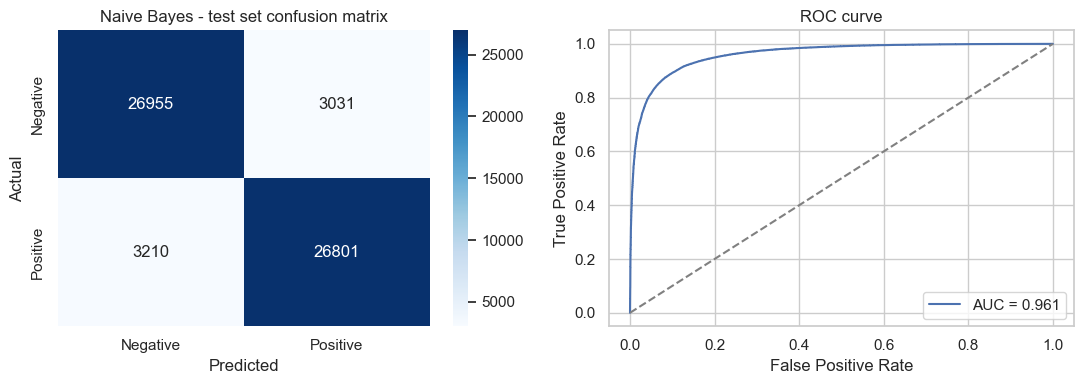

In [6]:
final_model = grid.best_estimator_
start = time.time()
final_model.fit(train_df["clean_text"], y_train)
nb_train_time = round(time.time() - start, 1)
print(f"training time: {nb_train_time} s")

y_pred = final_model.predict(test_df["clean_text"])
y_prob = final_model.predict_proba(test_df["clean_text"])[:, 1]

acc, prec = accuracy_score(y_test, y_pred), precision_score(y_test, y_pred)
rec, f1 = recall_score(y_test, y_pred), f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC AUC  : {auc:.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], digits=4))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title("Naive Bayes - test set confusion matrix")
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC curve"); axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "nb_confusion_matrix_roc.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations (section 4)**

- On the test set (59,997 reviews) the final model reaches accuracy 0.8960, precision 0.8984, recall 0.8930, F1 0.8957 and ROC-AUC 0.9608.
- The test F1 is 0.54 points above the CV F1 (0.8903), because the final model was trained on 239,986 reviews instead of about 80,000 per CV fold.
- There are 6,241 errors (10.40 %): 3,031 negative reviews predicted as positive and 3,210 positive reviews predicted as negative. The model misses slightly more positive reviews, so recall (0.8930) is a little lower than precision (0.8984).

## 5. Model interpretation and error analysis
For Naive Bayes, the difference between the class log-probabilities of each feature shows which words push a review towards each class.

Top negative features:
             feature  log_ratio
           waste of     -4.032
     complete waste     -3.919
  very disappointed     -3.893
         waste your     -3.887
         worst book     -3.842
          don waste     -3.839
         what waste     -3.768
         money back     -3.734
 very disappointing     -3.677
            of junk     -3.641
          not worth     -3.602
       poor quality     -3.586
       this garbage     -3.582
          save your     -3.550
what disappointment     -3.550

Top positive features:
              feature  log_ratio
             is must      3.533
            must for      3.505
      only complaint      3.365
          also great      3.209
definitely recommend      3.017
         great value      2.905
          great read      2.866
    definitely worth      2.863
   excellent product      2.861
      wonderful book      2.861
      was pleasantly      2.857
          well worth      2.843
        awesome this      2.831
      n

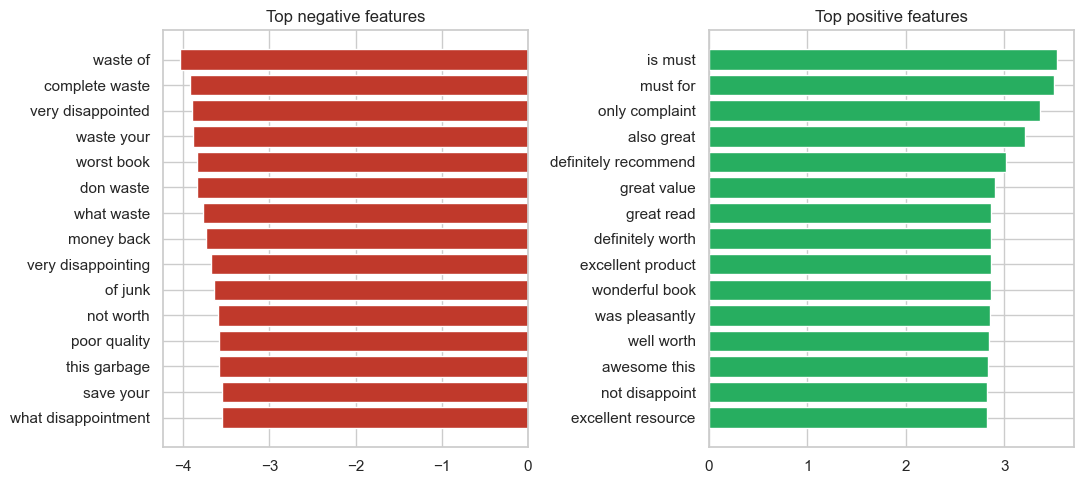


Total errors: 6241 of 59997

Error rate by review length:
                 mean   sum  count
length_bucket                     
short          0.0862  1739  20171
medium         0.1005  2014  20048
long           0.1258  2488  19778

Most confident mistakes:

True=1  Pred=0  P(positive)=0.001
Lifetime Warranty: Arrived DOA would not power-on. Amazon replaced the product even before I returned the old one (five stars). What service. Unfortunately the replacement would not fully charge (either the battery or the charger was bad), but the unit did work. Amazon would not send a third after t

True=1  Pred=0  P(positive)=0.003
Broke after two months but they sent a new one: I sent the product back to them, since it was under warranty. They sent me a brand new one right away, and this one has worked fine for the last year or so.(Original review) My daughter received this gift and loved playing with it. She particularly lik

True=1  Pred=0  P(positive)=0.003
I got a big mouth first then got 

In [7]:
tfidf_fit = final_model.named_steps["tfidf"]
nb_fit = final_model.named_steps["nb"]
names = np.array(tfidf_fit.get_feature_names_out())
log_ratio = nb_fit.feature_log_prob_[1] - nb_fit.feature_log_prob_[0]
order = np.argsort(log_ratio)

top_neg = pd.DataFrame({"feature": names[order[:15]], "log_ratio": log_ratio[order[:15]]})
top_pos = pd.DataFrame({"feature": names[order[-15:][::-1]], "log_ratio": log_ratio[order[-15:][::-1]]})
print("Top negative features:\n", top_neg.round(3).to_string(index=False))
print("\nTop positive features:\n", top_pos.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].barh(top_neg["feature"][::-1], top_neg["log_ratio"][::-1], color="#c0392b")
axes[0].set_title("Top negative features")
axes[1].barh(top_pos["feature"][::-1], top_pos["log_ratio"][::-1], color="#27ae60")
axes[1].set_title("Top positive features")
plt.tight_layout()
plt.savefig(FIG_DIR / "nb_top_features.png", dpi=150, bbox_inches="tight")
plt.show()

err = pd.DataFrame({"true": y_test.values, "pred": y_pred, "prob": y_prob,
                    "word_count": test_df["word_count"].values, "text": test_df["text"].values})
err["wrong"] = err["true"] != err["pred"]
err["length_bucket"] = pd.qcut(err["word_count"], q=3, labels=["short", "medium", "long"])
print("\nTotal errors:", err["wrong"].sum(), "of", len(err))
print("\nError rate by review length:")
print(err.groupby("length_bucket", observed=True)["wrong"].agg(["mean", "sum", "count"]).round(4))

wrong = err[err["wrong"]].copy()
wrong["confidence"] = (wrong["prob"] - 0.5).abs()
print("\nMost confident mistakes:")
for _, r in wrong.sort_values("confidence", ascending=False).head(5).iterrows():
    print(f"\nTrue={r['true']}  Pred={r['pred']}  P(positive)={r['prob']:.3f}")
    print(r["text"][:300])

**Observations (section 5)**

- The strongest features are bigrams. Negative: "waste of", "complete waste", "very disappointed", "worst book". Positive: "is must", "must for", "definitely recommend", "great value".
- "not disappoint" is a positive feature, so bigrams handle some negation.
- The error rate increases with review length: 8.62 % for short, 10.05 % for medium and 12.58 % for long reviews. Long reviews often contain both praise and complaints.
- Many of the most confident mistakes are mixed reviews (for example, the product broke but the seller replaced it and the customer was happy). Some look mislabelled, such as "Another great book from JoAnn Mapson", which is labelled negative.

## 6. Summary of results and saving

In [8]:
rows = []
for _, r in variants_df.iterrows():
    name = f"MultinomialNB, {r['text_column']}, ngram {r['ngram_range']}, alpha=1.0"
    if r["text_column"] == "processed_text" and r["ngram_range"] == "(1, 1)":
        name = "BASELINE: " + name
    rows.append({"model_variant": name, "validation": "5-fold CV (100k dev subset)",
                 "accuracy": r["cv_accuracy"], "f1": r["cv_f1"], "roc_auc": None})
rows.append({"model_variant": f"Tuned (GridSearchCV): {grid.best_params_}",
             "validation": "5-fold CV (100k dev subset)",
             "accuracy": None, "f1": round(grid.best_score_, 4), "roc_auc": None})
rows.append({"model_variant": "FINAL: best Naive Bayes on full training set",
             "validation": f"Held-out test set ({len(test_df):,} reviews)",
             "accuracy": round(acc, 4), "f1": round(f1, 4), "roc_auc": round(auc, 4)})
summary = pd.DataFrame(rows)
summary.to_csv(OUT_DIR / "nb_model_summary.csv", index=False)
cv_table.to_csv(OUT_DIR / "nb_gridsearch_results.csv", index=False)
joblib.dump(final_model, OUT_DIR / "nb_final_model.joblib")
print("Saved:", OUT_DIR / "nb_model_summary.csv")

# save the final result for the group comparison (same format in all six notebooks)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
result = {
    "model": "Naive Bayes", "student_id": STUDENT_ID,
    "accuracy": round(accuracy_score(y_test, y_pred), 4),
    "precision": round(precision_score(y_test, y_pred), 4),
    "recall": round(recall_score(y_test, y_pred), 4),
    "f1": round(f1_score(y_test, y_pred), 4),
    "f1_macro": round(f1_score(y_test, y_pred, average="macro"), 4),
    "roc_auc": round(roc_auc_score(y_test, y_prob), 4),
    "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    "cv_f1_mean": round(grid.best_score_, 4),
    "cv_f1_std": round(grid.cv_results_["std_test_score"][grid.best_index_], 4),
    "train_time_s": nb_train_time, "n_train": len(train_df),
    "best_params": str({k: (type(v).__name__ if k == "nb" else v) for k, v in grid.best_params_.items()}), "notes": "Tuned on 100k dev subset with 5-fold CV",
}
pd.DataFrame([result]).to_csv(os.path.join(METRICS_DIR, "Naive_Bayes.csv"), index=False)
print("Saved:", os.path.join(METRICS_DIR, "Naive_Bayes.csv"))

pd.set_option("display.max_colwidth", 90)
summary

Saved: ..\results\outputs\nb_model_summary.csv
Saved: ..\results\final_metrics\Naive_Bayes.csv


,model_variant,validation,accuracy,f1,roc_auc
0,"MultinomialNB, clean_text, ngram (1, 2), alpha=1.0",5-fold CV (100k dev subset),0.8879,0.8876,NaN
1,"MultinomialNB, processed_text, ngram (1, 2), alpha=1.0",5-fold CV (100k dev subset),0.8664,0.8673,NaN
2,"MultinomialNB, clean_text, ngram (1, 1), alpha=1.0",5-fold CV (100k dev subset),0.8458,0.8429,NaN
3,"BASELINE: MultinomialNB, processed_text, ngram (1, 1), alpha=1.0",5-fold CV (100k dev subset),0.8376,0.8363,NaN
4,"Tuned (GridSearchCV): {'nb': ComplementNB(), 'nb__alpha': 1.0, 'tfidf__ngram_range': (...",5-fold CV (100k dev subset),NaN,0.8903,NaN
5,FINAL: best Naive Bayes on full training set,"Held-out test set (59,997 reviews)",0.8960,0.8957,0.9608


## 7. Live prediction on new reviews

In [9]:
def predict_review(review_text):
    prob = final_model.predict_proba([clean_text(review_text)])[0]
    label = "Positive" if prob[1] >= 0.5 else "Negative"
    print(f"Review: '{review_text}'")
    print(f"Prediction: {label} ({max(prob) * 100:.2f}% confidence)\n")

predict_review("This product is amazing! Works smoothly and arrived on time.")
predict_review("Terrible product. Stopped working after two days.")
predict_review("Not bad for the price.")

Review: 'This product is amazing! Works smoothly and arrived on time.'
Prediction: Positive (93.69% confidence)

Review: 'Terrible product. Stopped working after two days.'
Prediction: Negative (99.52% confidence)

Review: 'Not bad for the price.'
Prediction: Negative (52.65% confidence)



## 8. Conclusion

Naive Bayes was trained on the shared sample (239,986 training and 59,997 test reviews).

- Keeping stop words and adding bigrams raised the CV F1 from 0.8363 (baseline) to 0.8876.
- GridSearchCV selected ComplementNB, alpha = 1.0, bigrams and sublinear tf (CV F1 0.8903).
- On the test set the final model scored accuracy 0.8960, F1 0.8957 and ROC-AUC 0.9608.

**Strengths:** very fast to train, simple, and gives class probabilities.

**Limitations:** Naive Bayes assumes the words are independent of each other, so it cannot use word order beyond bigrams. Its F1 is 3.53 points below the Linear SVM (0.8957 vs 0.9310).